# E63: Do fine-tunes built to elicit sit on fewer MLP neurons than those built to teach something new?


## The answer

No. No reading of neurons tells the two kinds apart on all the pairs we tried. A finished update is spread almost evenly over the neurons, whichever kind built it, and no fine-tune rescales the neurons the original model already has. Activation shifts and the neurons that carry the gain sit narrower for elicit on two of the three families, and wider on the third. On the main pair, the gap in carrying neurons closes once the cipher has learned as much.


## What we were trying to test

A VPD decomposition appears to tell a fine-tune that strengthens something the original model does from one that teaches it something new. If simply counting MLP neurons did the same, nobody would need the decomposition. So we asked whether fine-tunes built to elicit sit on fewer neurons, in any of five senses.

Here "built to elicit" means only how the task was built: its targets are something the original model is close to doing. It is not the causal label of `decisions.md` row 112, where elicitation means the behaviour runs through a mechanism the original model already has. None of these pairs has had a causal check.

Nothing was trained. We read 26 saved full-weight fine-tunes of three families, plus one update that learned nothing.

- **Family A, the main pair.** Both tasks map a key word to a value word after a rare marker. The elicit map's values are words the model already ranks 2nd to 20th. The cipher's are words it almost never predicts. Five seeds each at the same update size, so the cipher has learned less. Two seeds of the cipher at its own learned step, so that both have learned the table.
- **Family B.** Key tables again: the same word back against a random word, both at step 10, two seeds each.
- **Family C.** Broad text tasks at step 300: continuing lowercased text against a 500-word cipher, two seeds each.

A neuron is one of the 12288 GELU outputs across the four blocks. The five readings, each with what it is compared against:

- **Spread of the update.** The participation ratio of each neuron's squared weight change $e_i$, $(\sum e_i)^2 / \sum e_i^2$, as a fraction of 12288. It reads 1 if all neurons change equally. An update on 16 neurons reads 0.0013. Compared with the same reading after a random rotation of the neuron index, which says whether the neuron basis is special.
- **Spread of the first gradient.** The same reading on the task's gradient on the fine-tune's first batch at the original weights, because Adam flattens the finished update. Compared with the same batch with its targets shuffled.
- **Rescale share.** The share of the update lying along each neuron's own original weights. It reads 1 for pure rescaling and about 1/768 for a random change.
- **Spread of the activation shift.** The participation ratio of one window's squared fine-tuned minus original activation at the answer position, median over windows. Compared with a Gaussian update of the same norms on the same matrices, and with the rotated value.
- **Neurons that carry the gain.** On each window, rank neurons by that window's own shift, and give the top k the fine-tuned activations in an original-model forward pass. The count is log base 2 of the k at which the rise in the target's log probability reaches half of what all neurons give for that state. Compared with a random order of the neurons.

A reading answers yes only if it passes four tests and a guard. Elicit must be the sparser side at matched size, at equal progress and on each other family. Each gap must beat the seed spread and the same gap on the reference. The guard asks that elicit also lies on the sparser side of the reference itself.

One disclosure. While reviewing the code, the reviewer computed the update's spread and its rotated value on all 26 states, before the rules were amended. So that reading's outcome, no yes and elicit denser in every family, was known before the amendments were filed. No other number was read.


## What we expected, and why

- **The spread of the update will not answer yes.** Adam normalises each weight's step, which flattens any update. This was not a blind prediction, as disclosed above.
- **The rescale share will not answer yes.** We had no reason to think a few steps of Adam align with each neuron's existing weights.
- **The count of neurons will separate at matched size and not at equal progress.** The earlier neuron patching on family A, which ranked neurons by their mean shift over all windows, behaved so. That run found 4096 neurons for half the gain on elicit and 12288 on the matched cipher, and the gap went when the cipher had learned as much.
- **The first gradient and the activation shift: no lean.** Both were left open.


## What we observed

### Is the update itself on fewer neurons when built to elicit?


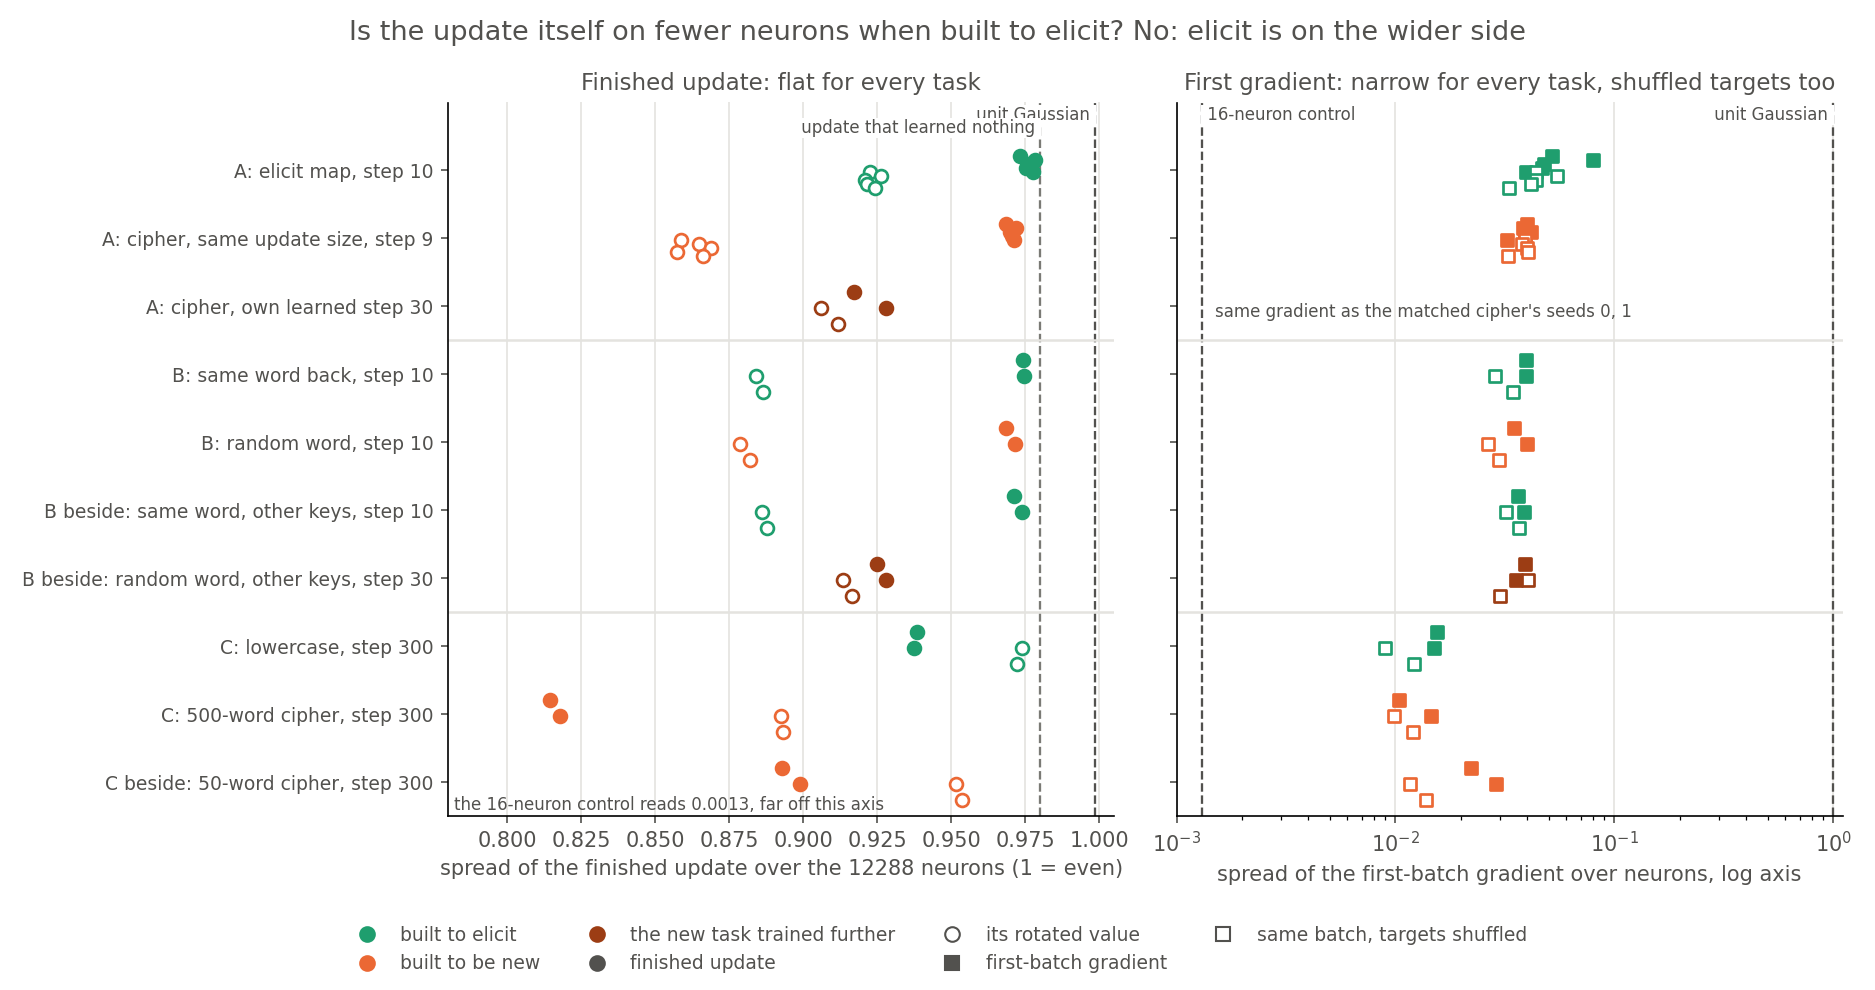

In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/neuron_sparsity/figures")
display(Image(filename=str(FIG / "update_sparsity.png")))


**Reading it.** No: elicit is the wider side in every family, for the finished update and for the first gradient. The left panel shows finished updates near 1, where the elicit map reads 0.976 and the matched cipher 0.970. An update that learned nothing reads 0.980, so being this flat says nothing about the task. Rotating the neuron index narrows the elicit map to 0.923, so on this task the neuron basis is wider than a random basis. The right panel shows first gradients about twenty times narrower, 0.053 on elicit and 0.038 on the cipher, a gap under the seed spread. Shuffled targets read much the same, 0.043 on elicit, so this narrowness does not depend on the task's targets. Adam's flattening remains the filed explanation of the difference between the panels; no SGD fine-tune was run to test it.


### Do fine-tunes rescale the neurons the original model already has?


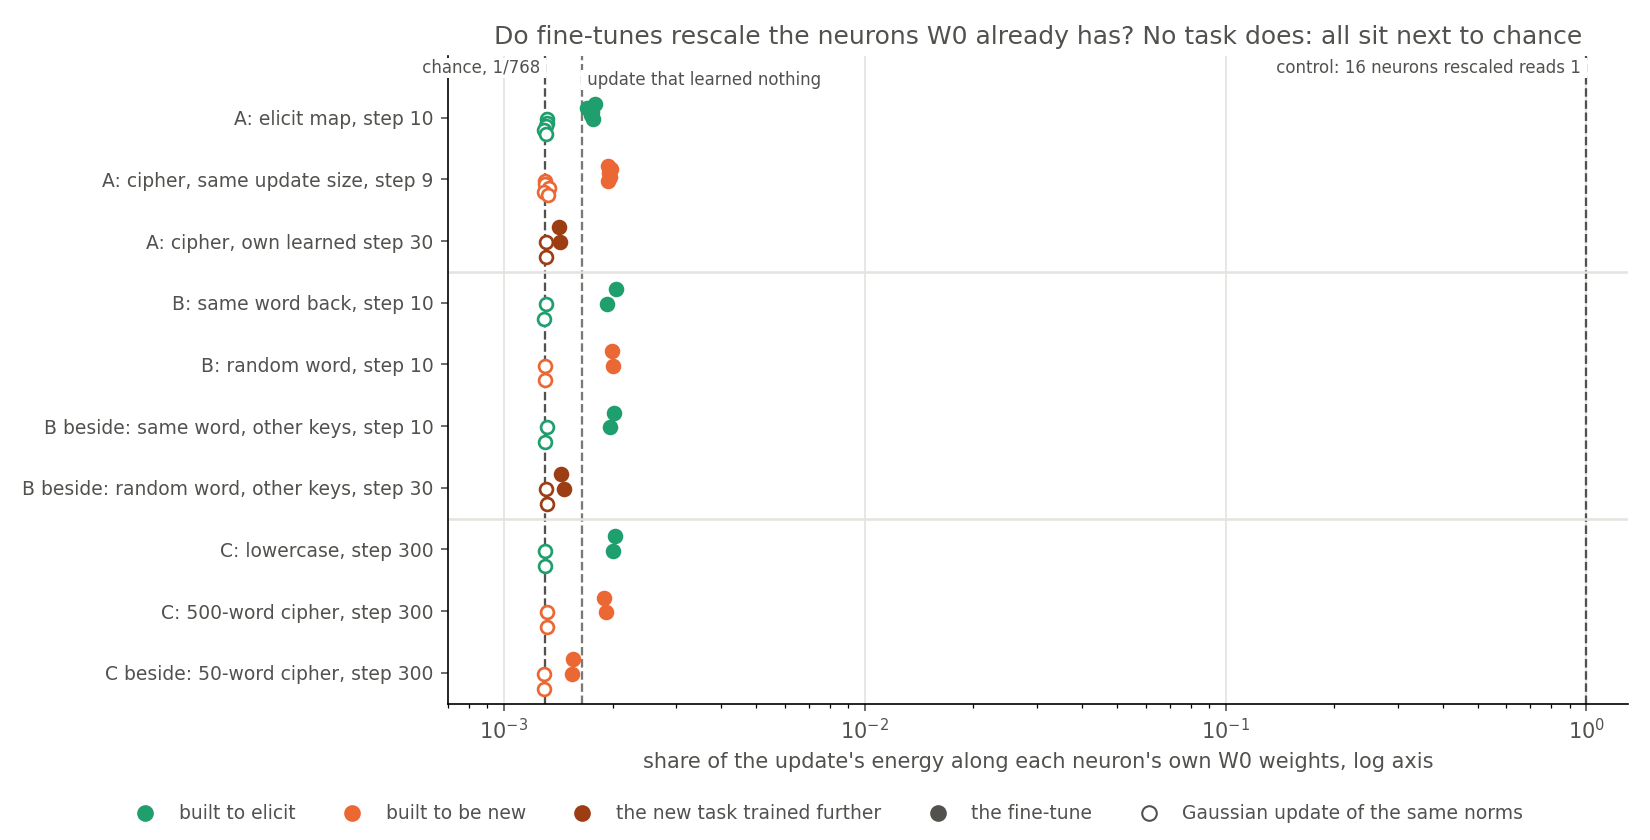

In [2]:
display(Image(filename=str(FIG / "rescale_share.png")))


**Reading it.** No task does. All the fine-tunes read between 0.0014 and 0.0020, next to the Gaussian's 0.0013, while the control that rescales 16 neurons reads 1. Elicit beats its reference at equal progress and on family C, but those gaps are a few ten-thousandths. On family A at matched size the cipher reads higher, 0.0020 against 0.0017. The more trained updates read lower, cipher 0.0020 at step 9 and 0.0014 at step 30, so the reading moves with training at least as much as with kind.


### Does the activation shift sit on fewer neurons when built to elicit?


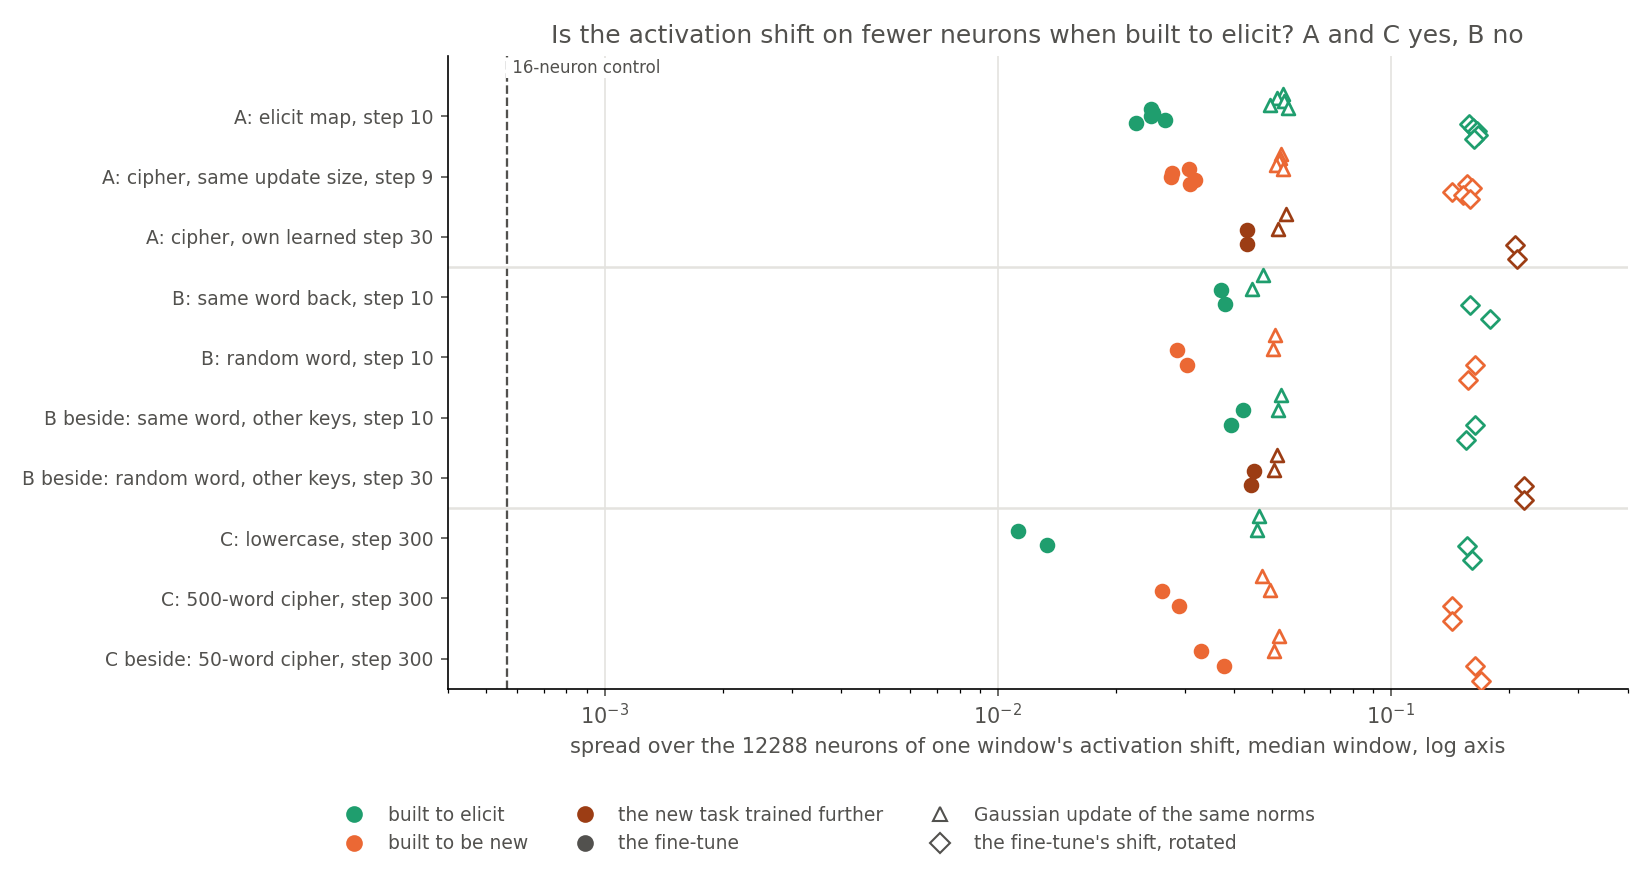

In [3]:
display(Image(filename=str(FIG / "activation_sparsity.png")))


**Reading it.** On families A and C yes, on family B the reverse. The elicit map shifts about 300 effective neurons per window and the matched cipher about 370, a gap just over the seed spread. Lowercase shifts about 150 and the broad cipher about 340. On family B the same-word table shifts about 460 and the random table about 360, so elicit is the wider side there. This is the only reading that passes at matched size. It is not a progress effect, since the gap widens at equal progress: the trained cipher shifts about 530 neurons. That test fails only because the rotated value widens more. A Gaussian update of the same norms already shifts only about 650 neurons, so a low level alone says little about the fine-tune. The control, an update on 16 neurons, shifts about 7.


### How many neurons carry the gain on the main pair?


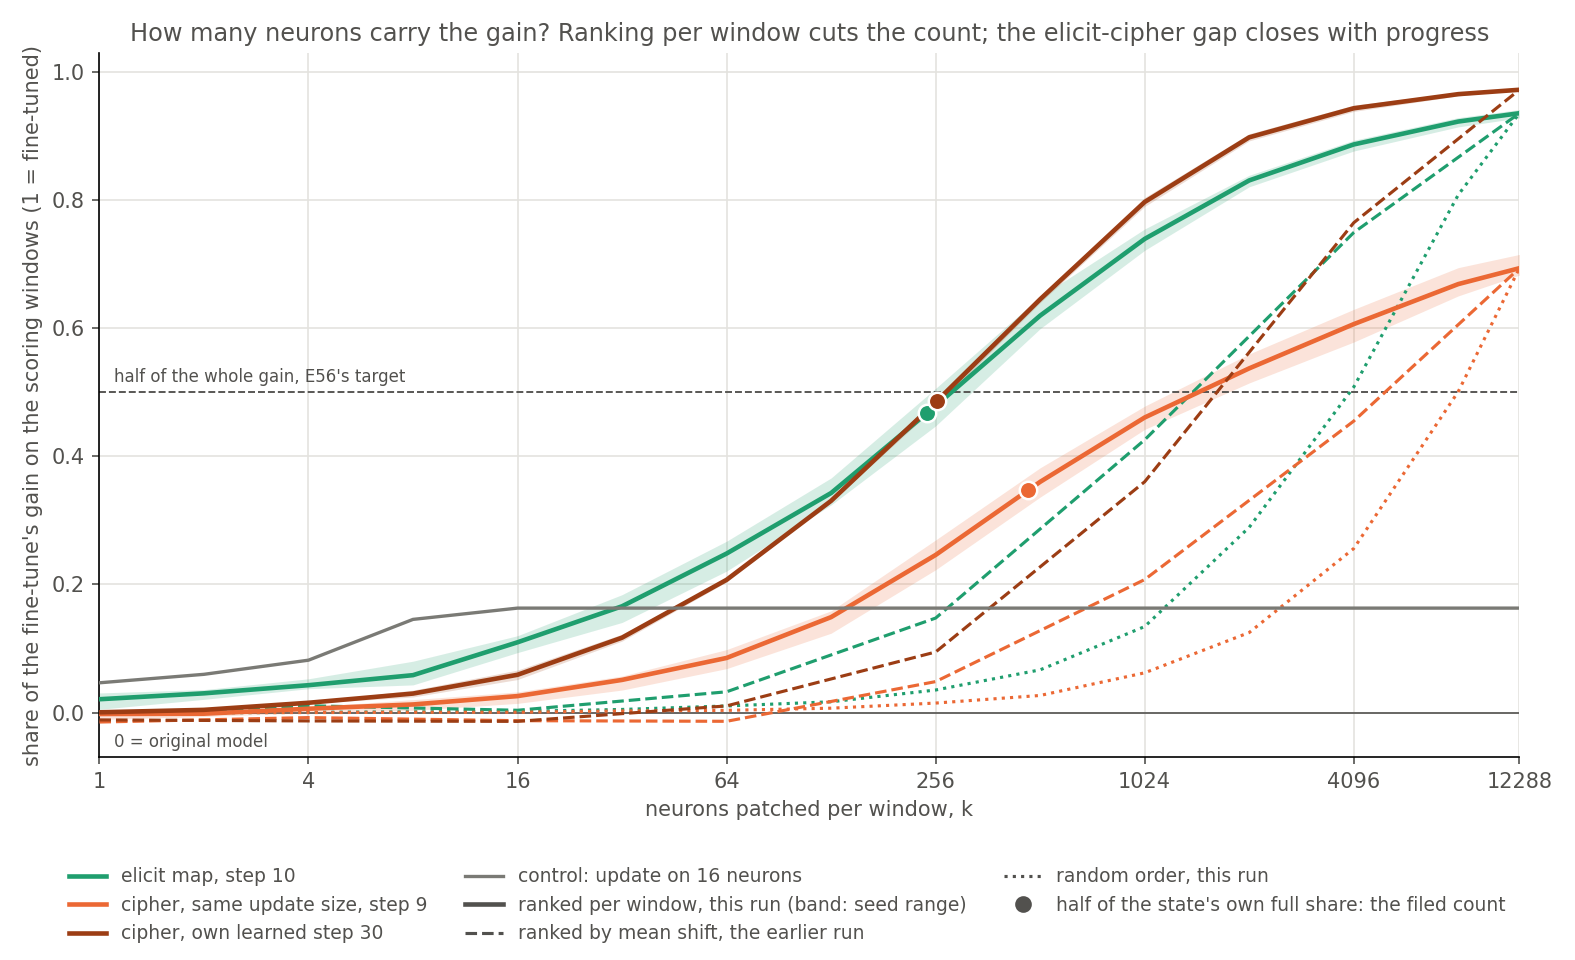

In [4]:
display(Image(filename=str(FIG / "c1_family_a.png")))


**Reading it.** Fewer neurons than the earlier run found, for both kinds, and the elicit gap misses the filed floor by a hair, then closes with progress. Half of each state's own full share needs about 240 neurons on the elicit map and about 470 on the matched cipher. That gap is 0.97 in log base 2, under the filed floor of 1, though no elicit seed overlaps a cipher seed. At equal progress it shrinks to 0.17: the cipher at its own step needs about 260. The control update on 16 neurons reaches its half at about 4, and a random order needs thousands. Solid lines against dashed show what per-window ranking changed. At 256 neurons the elicit map carries 0.48 of its gain ranked per window, against 0.15 ranked by mean shift. That fits different keys using different neurons, though the distinct neurons over all windows were not counted. The earlier run's gap was 1.58, on its target of half the whole gain and a coarse grid. On that target, unfiled here, these curves put elicit near 280 and the matched cipher near 1450, a gap of 2.4. That gap also vanishes at equal progress. So the pattern matches the earlier run and the counts are far lower.


### Does the same count hold on the other pairs?


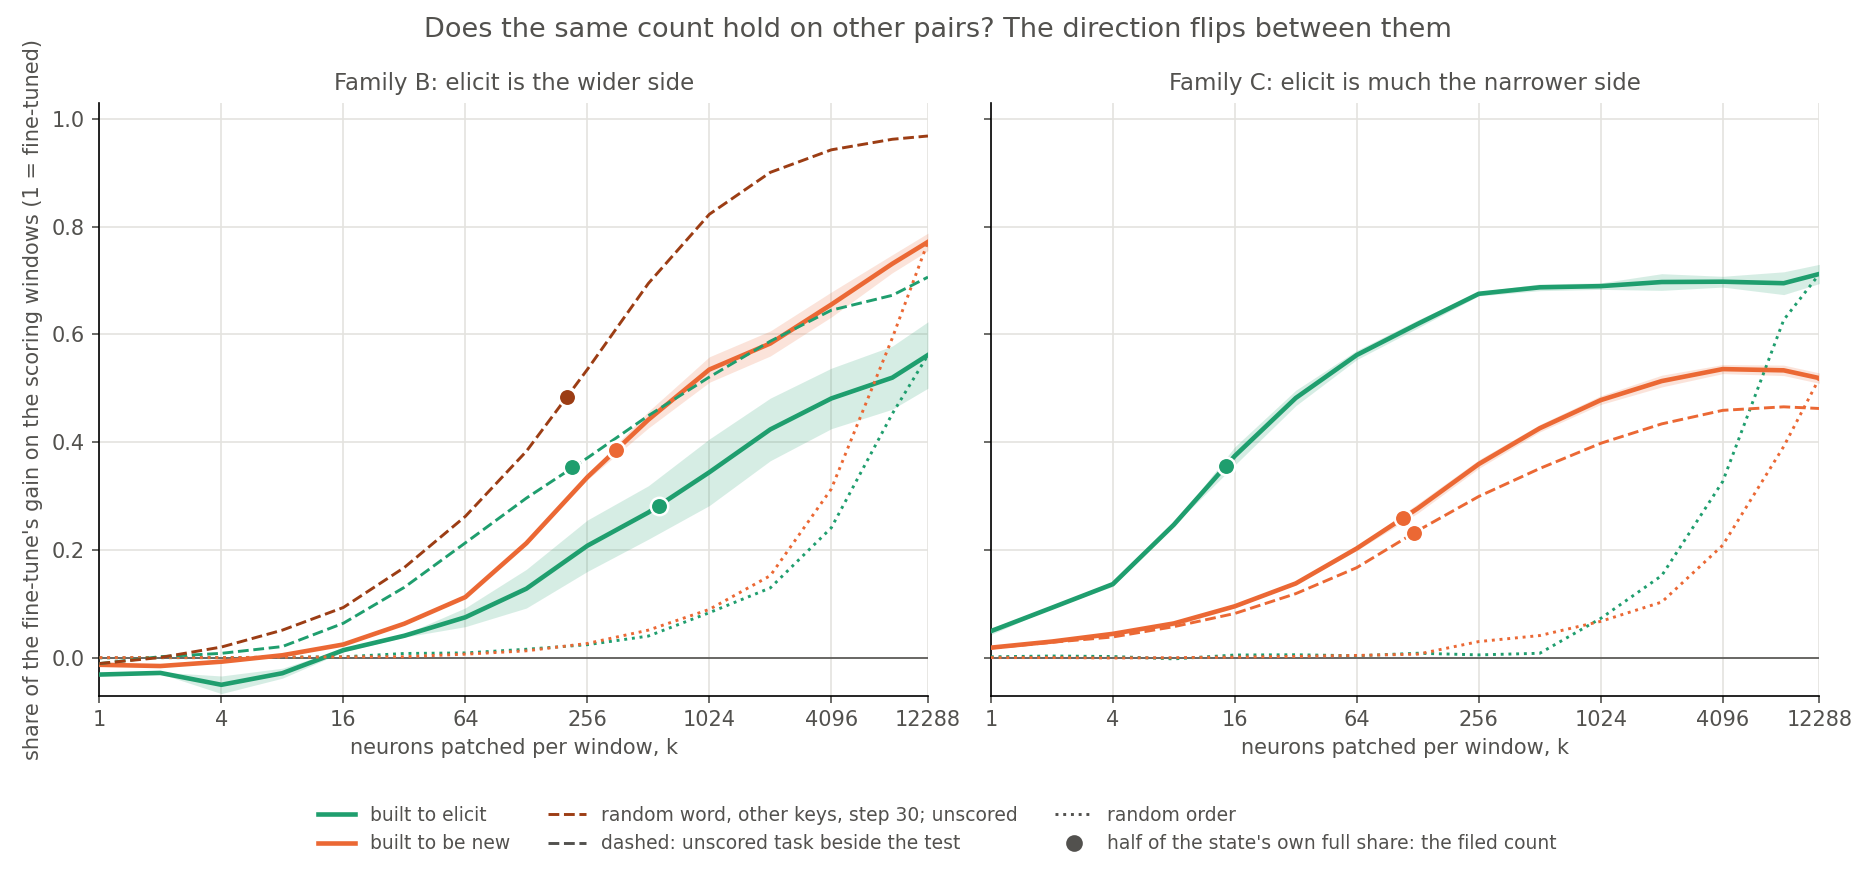

In [5]:
display(Image(filename=str(FIG / "c1_families_bc.png")))


**Reading it.** No, the direction flips. On family B elicit is the wider side, about 580 neurons against 360, under the floor. The second same-word table, on other keys, reads about 210, so two tables built the same way differ by more than the kinds do. On family C lowercase needs about 15 neurons and the broad cipher about 110, the only clear pass of this reading. The 50-word cipher reads about 120, so the two ciphers agree. Still, that test compares one elicit task with one or two new tasks. A pass reads "these tasks differ, in this direction", not "this kind is sparser". Lowercase also gains only half what the broad cipher does, and whether that matters was not tested.


## What we learned

Neurons do not map eliciting more cleanly, at this size and on these pairs. Weight updates are no use for this: they are flat after Adam and do not align with existing neurons. Activation shifts and per-window counts do differ between tasks, by more than seeds. But the direction differs between families, and each family compares very few tasks. Ranking per window shows that gain sits on far fewer neurons per window than the earlier run suggested, for both kinds. The decomposition's share of the gain carried by changed CI values still separates family A at equal progress, 0.76 against 0.25 in the earlier run. That share was not read on the other two families here, and it has no causal check yet either.


## How compelling is the evidence

The controls all held. Rules, tests and verdicts were recomputed from the per-state values and match the scored file exactly.

What each reading cannot see:

- **Spread of the update:** attention and read-out matrices, and anything Adam's flattening hides.
- **Spread of the first gradient:** later steps, what Adam then does, and progress. On family C it may mostly read ordinary text.
- **Rescale share:** a neuron rotating towards another neuron.
- **Spread of the activation shift:** neurons that move and do nothing.
- **Neurons that carry the gain:** changes to a neuron's output weights, which stay at the original values. It also counts per window, so the distinct neurons over all windows are not read.

The largest limit is the design. Family A, family C and the equal-progress test each compare one task with another, and seeds barely move these numbers, so almost any two tasks separate. A simulated false yes under no kind effect was about 2% per reading and 9% over five. Passes therefore read "these tasks differ, in this direction". A null here is scoped to these 26 states, three families, the 67M model, and Adam fine-tunes.


## Surprises

No filed prediction reversed. One missed narrowly: the count of neurons was filed to pass at matched size, and its gap of 0.97 fell under the floor of 1, with its direction as filed.

Three things no prediction covered:

- The direction flips on family B for both the activation shift and the count. The cause is not established.
- With more training on the cipher the activation shift spreads while the neurons needed fall. We did not test why.
- The first gradient is about as narrow for shuffled targets as for true ones. No value had been filed for this.


## What next

- **The truth-set reading needs the user's say.** The tree leaves it open. If the activation shift and the count follow a causal label there, neurons return as a rival.
- **Re-read these numbers on any pair that gets a causal check.** It costs nothing on saved states. If direction then follows the label, family B's flip was about its label.
- **Read the elicit map at another step.** The progress reading rests on the cipher alone. A count that falls on elicit too would support it.


## Scorecard

W1 update spread, W1g first-gradient spread, W2 rescale share, A1 activation-shift spread, C1 neurons carrying the gain. T1 family A at matched size, T2 equal progress, T3_B family B, T3_C family C; the guard is elicit against the reference. A test passes only if it separates, elicit is sparser, and it beats the reference's gap. Means are elicit against new.

| number | T1 | T2 | T3_B | T3_C | guard | yes? |
|---|---|---|---|---|---|---|
| W1 | fail 0.976 / 0.970 | fail 0.976 / 0.922 | fail 0.974 / 0.970 | fail 0.938 / 0.816 | fail 0.976 / rotated 0.923 | no |
| W1g | fail 0.053 / 0.038 | fail 0.066 / 0.039 | fail 0.040 / 0.037 | fail 0.015 / 0.012 | fail 0.053 / shuffled 0.043 | no |
| W2 | fail 0.00175 / 0.00196 | **pass** 0.00174 / 0.00143 | fail 0.00199 / 0.00199 | **pass** 0.00202 / 0.00191 | **pass** 0.00175 / Gaussian 0.00131 | no |
| A1 | **pass** 0.0246 / 0.0298 | fail 0.0247 / 0.0430 | fail 0.0375 / 0.0294 | **pass** 0.0123 / 0.0276 | **pass** Gaussian 0.0525, rotated 0.163 | no |
| C1 | fail 7.92 / 8.88 | fail 7.84 / 8.01 | fail 9.18 / 8.48 | **pass** 3.86 / 6.76 | **pass** 7.92 / random 11.82 | no |

| lean | filed | rule | read | verdict |
|---|---|---|---|---|
| P1 | W1 does not answer yes, Adam flattens it | W1 yes is false | false; known before the amendments | right, not blind |
| P2 | W1g unknown | none | fails every test | no lean to score |
| P3 | W2 does not answer yes | W2 yes is false | false | right |
| P4 | A1 unknown | none | passes T1, T3_C, guards; fails T2, T3_B | no lean to score |
| P5 | C1 passes T1, fails T2 | C1 T1 passes and T2 fails | T1 fails, gap 0.965 under floor 1; T2 fails | **missed**, narrowly |


## Not run

SGD fine-tunes of these pairs, for which the first gradient stands in. Attention-head sparsity. Any new fine-tune. Qwen. The causal label of `decisions.md` row 112, which E64 and E55 pursue. The truth-set reading. The first-gradient reading on task text minus cased rows on family C. The elicit map at any other step. The count of distinct neurons over all windows. r on families B and C in this run.

## Departures from the literature

Neuron patching departs from causal tracing, Meng et al. 2022: fine-tuned activations go into the same input's original-model run at every position, ranked here per window by shift size, read as a share of a gain. The participation ratio is the standard form applied to neuron energies; no paper's procedure was followed. The rotated, shuffled and random-order references, and every threshold, are this project's. Full list in the report.

## Provenance

Report `reports/analyses/2026-11-02_analysis_e63-neuron-sparsity.md`. Results `experiments/neuron_sparsity/results/`. Job 48527, MATS debug QoS, L40, 2 min 12 s, peak 7.5 GB, $0. Code at de14090, unchanged in 5727b38; results committed in 1132c03.
